In [1]:
import os
from pathlib import Path

os.chdir(Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd())

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib_venn import venn3
from matplotlib.patches import Patch

deg_30219 = pd.read_csv('./results/DEG/GSE30219_DEG_results_strict.csv', index_col=0)
deg_149507 = pd.read_csv('./results/DEG/GSE149507_DEG_results_strict.csv', index_col=0)
deg_60052 = pd.read_csv('./results/DEG/GSE60052_DEG_results_strict.csv', index_col=0)

print(f"GSE30219 DEGs: {len(deg_30219)}")
print(f"GSE149507 DEGs: {len(deg_149507)}")
print(f"GSE60052 DEGs: {len(deg_60052)}")

GSE30219 DEGs: 3221
GSE149507 DEGs: 3145
GSE60052 DEGs: 3356


In [5]:
up_30219 = set(deg_30219[deg_30219['log2FC'] > 0].index)
down_30219 = set(deg_30219[deg_30219['log2FC'] < 0].index)

up_149507 = set(deg_149507[deg_149507['log2FC'] > 0].index)
down_149507 = set(deg_149507[deg_149507['log2FC'] < 0].index)

up_60052 = set(deg_60052[deg_60052['log2FC'] > 0].index)
down_60052 = set(deg_60052[deg_60052['log2FC'] < 0].index)

consensus_up = up_30219 & up_149507 & up_60052

consensus_down = down_30219 & down_149507 & down_60052

print(f"Consensus upregulated: {len(consensus_up)}")
print(f"Consensus downregulated: {len(consensus_down)}")
print(f"Total consensus DEGs: {len(consensus_up) + len(consensus_down)}")

Consensus upregulated: 499
Consensus downregulated: 786
Total consensus DEGs: 1285


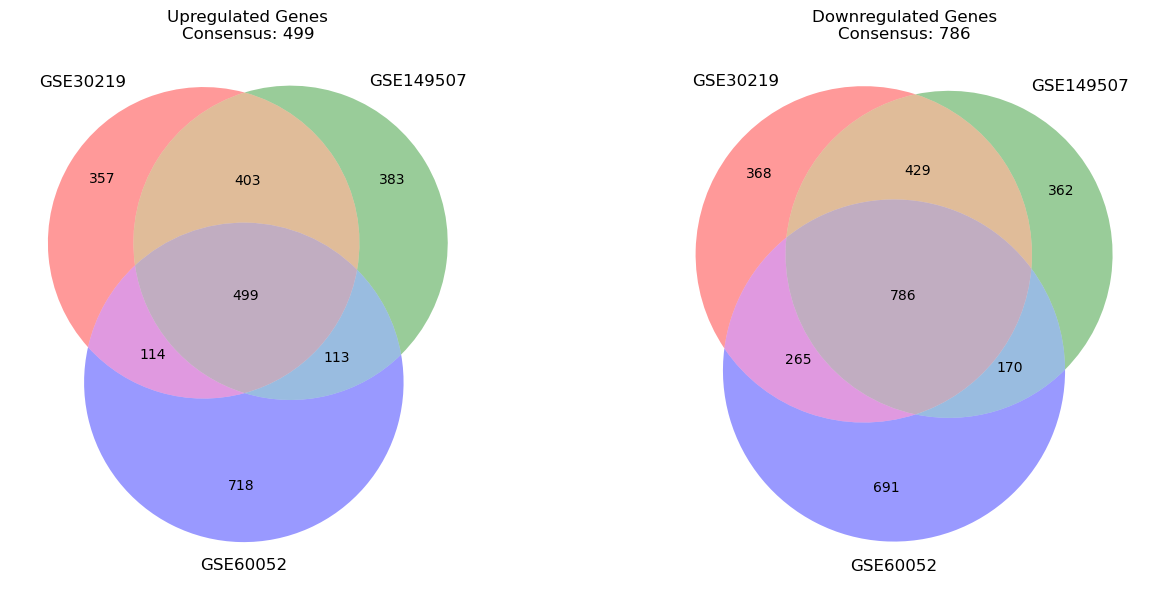

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

plt.sca(axes[0])
venn3([up_30219, up_149507, up_60052],
      set_labels=('GSE30219', 'GSE149507', 'GSE60052'))
axes[0].set_title(f'Upregulated Genes\nConsensus: {len(consensus_up)}')

plt.sca(axes[1])
venn3([down_30219, down_149507, down_60052],
      set_labels=('GSE30219', 'GSE149507', 'GSE60052'))
axes[1].set_title(f'Downregulated Genes\nConsensus: {len(consensus_down)}')

plt.tight_layout()
plt.savefig('./figures/consensus_DEG_venn.png', dpi=150)
plt.show()

In [9]:
consensus_up_df = pd.DataFrame({'Gene': list(consensus_up), 'direction': 'Up'})
consensus_down_df = pd.DataFrame({'Gene': list(consensus_down), 'direction': 'Down'})
consensus_df = pd.concat([consensus_up_df, consensus_down_df])
consensus_df.to_csv('./results/DEG/consensus_DEGs.csv', index=False)
print("Saved!")

Saved!


In [11]:
deg_69091 = pd.read_csv('./results/DEG/GSE69091_DEG_results_strict.csv', index_col=0)
print(f"GSE69091 DEGs: {len(deg_69091)}")
print(deg_69091.head())

GSE69091 DEGs: 436
            logFC   AveExpr          t       P.Value     adj.P.Val          B
Fmo1     5.544973  8.326880  55.180812  9.271888e-12  2.285242e-07  15.340229
Olfml2a  4.779212  8.206391  48.068461  2.838487e-11  3.498010e-07  14.822786
Lifr     3.646324  8.602595  39.555155  1.376461e-10  9.020074e-07  13.947622
Stom     4.735692  8.885677  38.215204  1.819159e-10  9.020074e-07  13.775257
Hhip     5.183371  7.610555  38.093680  1.866644e-10  9.020074e-07  13.759062


In [13]:
import mygene
mg = mygene.MyGeneInfo()

mouse_genes = deg_69091.index.tolist()

result = mg.querymany(mouse_genes, 
                      scopes='symbol', 
                      fields='symbol', 
                      species='human',
                      as_dataframe=True)

print(result.shape)
print(result.head())

Input sequence provided is already in string format. No operation performed
Input sequence provided is already in string format. No operation performed
1 input query terms found dup hits:	[('Tec', 2)]
63 input query terms found no hit:	['8430408G22Rik', 'Gucy1a3', 'Galntl4', 'Slc9a3r1', 'Gm10808', 'Lect1', 'Gm266', 'March3', 'Fam118a'


(437, 4)
            _id     _score   symbol notfound
query                                       
Fmo1       2326  18.642810     FMO1      NaN
Olfml2a  169611  16.801609  OLFML2A      NaN
Lifr       3977  17.671598     LIFR      NaN
Stom       2040  17.677970     STOM      NaN
Hhip      64399  17.600334     HHIP      NaN


In [15]:
result = result[result['notfound'].isna()] 
result = result.dropna(subset=['symbol'])   

deg_69091['human_symbol'] = deg_69091.index.map(
    result['symbol'].to_dict()
)

deg_69091_human = deg_69091.dropna(subset=['human_symbol'])
deg_69091_human = deg_69091_human.set_index('human_symbol')

print(f"Mouse DEGs with human orthologs: {len(deg_69091_human)}")
print(deg_69091_human.head())

Mouse DEGs with human orthologs: 373
                 logFC   AveExpr          t       P.Value     adj.P.Val  \
human_symbol                                                              
FMO1          5.544973  8.326880  55.180812  9.271888e-12  2.285242e-07   
OLFML2A       4.779212  8.206391  48.068461  2.838487e-11  3.498010e-07   
LIFR          3.646324  8.602595  39.555155  1.376461e-10  9.020074e-07   
STOM          4.735692  8.885677  38.215204  1.819159e-10  9.020074e-07   
HHIP          5.183371  7.610555  38.093680  1.866644e-10  9.020074e-07   

                      B  
human_symbol             
FMO1          15.340229  
OLFML2A       14.822786  
LIFR          13.947622  
STOM          13.775257  
HHIP          13.759062  


In [17]:
notch_up = set(deg_69091_human[deg_69091_human['logFC'] > 0].index)
notch_down = set(deg_69091_human[deg_69091_human['logFC'] < 0].index)

print(f"Notch upregulated (human orthologs): {len(notch_up)}")
print(f"Notch downregulated (human orthologs): {len(notch_down)}")

down_rescued = consensus_down & notch_up

up_suppressed = consensus_up & notch_down

print(f"\nConsensus DOWN ∩ Notch UP (rescued): {len(down_rescued)}")
print(f"Consensus UP ∩ Notch DOWN (suppressed by Notch): {len(up_suppressed)}")

Notch upregulated (human orthologs): 290
Notch downregulated (human orthologs): 83

Consensus DOWN ∩ Notch UP (rescued): 48
Consensus UP ∩ Notch DOWN (suppressed by Notch): 7


In [19]:
from scipy.stats import fisher_exact

n_consensus_down = len(consensus_down)
n_consensus_up = len(consensus_up)
n_notch_up = len(notch_up)
n_notch_down = len(notch_down)
n_down_rescued = len(down_rescued)
n_up_suppressed = len(up_suppressed)
mat_30219 = pd.read_csv('./data/processed/GSE30219_expression_matrix.csv', index_col=0)
mat_149507 = pd.read_csv('./data/processed/GSE149507_filtered_expression_matrix_final.csv', index_col=0)
mat_60052 = pd.read_csv('./data/processed/GSE60052_expression_matrix.csv', index_col=0)

gene_universe = len(set(mat_30219.index) & set(mat_149507.index) & set(mat_60052.index))
print(f"Gene universe: {gene_universe}")

table = [[n_down_rescued, n_consensus_down - n_down_rescued],
         [n_notch_up - n_down_rescued, gene_universe - n_consensus_down - n_notch_up + n_down_rescued]]
odds_ratio, pvalue = fisher_exact(table, alternative='greater')
print(f"Rescue overlap — Odds ratio: {odds_ratio:.3f}, P-value: {pvalue:.6f}")

table2 = [[n_up_suppressed, n_consensus_up - n_up_suppressed],
          [n_notch_down - n_up_suppressed, gene_universe - n_consensus_up - n_notch_down + n_up_suppressed]]
odds_ratio2, pvalue2 = fisher_exact(table2, alternative='greater')
print(f"Suppression overlap — Odds ratio: {odds_ratio2:.3f}, P-value: {pvalue2:.6f}")

Gene universe: 15477
Rescue overlap — Odds ratio: 3.883, P-value: 0.000000
Suppression overlap — Odds ratio: 2.790, P-value: 0.017546


In [21]:
pd.DataFrame({'Gene': list(down_rescued)}).to_csv('./results/DEG/notch_rescued_consensus_down.csv', index=False)
pd.DataFrame({'Gene': list(up_suppressed)}).to_csv('./results/DEG/notch_suppressed_consensus_up.csv', index=False)

In [23]:
deg_43346 = pd.read_csv('./data/processed/GSE43346_expression_matrix.csv', index_col=0)
metadata_43346 = pd.read_csv('./data/metadata/GSE43346_metadata.csv', index_col=0)

print(deg_43346.shape)
print(metadata_43346['group'].value_counts())

(21655, 24)
group
SCLC      23
Normal     1
Name: count, dtype: int64


In [25]:
normal_sample = metadata_43346[metadata_43346['group'] == 'Normal'].index.tolist()
sclc_samples_43346 = metadata_43346[metadata_43346['group'] == 'SCLC'].index.tolist()

normal_expr = deg_43346[normal_sample[0]]  
sclc_mean = deg_43346[sclc_samples_43346].mean(axis=1)

log2fc_43346 = sclc_mean - normal_expr

print(f"Total genes: {len(log2fc_43346)}")
print(log2fc_43346.head())

Total genes: 21655
Gene Symbol
A1BG        0.283281
A1BG-AS1    0.428675
A1CF        1.382309
A2M        -3.191911
A2M-AS1    -0.572631
dtype: float64


In [27]:
consensus_down_43346 = log2fc_43346[log2fc_43346.index.isin(consensus_down)]
consensus_up_43346 = log2fc_43346[log2fc_43346.index.isin(consensus_up)]

down_concordant = (consensus_down_43346 < 0).sum()
up_concordant = (consensus_up_43346 > 0).sum()

print(f"Consensus DOWN genes in GSE43346: {len(consensus_down_43346)}")
print(f"Directionally concordant (negative FC): {down_concordant} ({down_concordant/len(consensus_down_43346)*100:.1f}%)")

print(f"\nConsensus UP genes in GSE43346: {len(consensus_up_43346)}")
print(f"Directionally concordant (positive FC): {up_concordant} ({up_concordant/len(consensus_up_43346)*100:.1f}%)")

Consensus DOWN genes in GSE43346: 786
Directionally concordant (negative FC): 778 (99.0%)

Consensus UP genes in GSE43346: 499
Directionally concordant (positive FC): 491 (98.4%)


In [29]:
validation_summary = pd.DataFrame({
    'direction': ['Downregulated', 'Upregulated'],
    'total_genes': [len(consensus_down_43346), len(consensus_up_43346)],
    'concordant': [down_concordant, up_concordant],
    'concordance_pct': [round(down_concordant / len(consensus_down_43346) * 100, 1),
                        round(up_concordant / len(consensus_up_43346) * 100, 1)]
})
validation_summary.to_csv('./results/DEG/GSE43346_directional_validation.csv', index=False)
print("Saved!")

Saved!
